# Build the exploration training mixtures (2D marine, 3D marine, 3D land)

This notebook builds the training files for the final model (`LSTM` bottleneck) on three exploration seismic datasets. It follows the recipe of `05_build_instance_mixtures`, and the output has the same format as the INSTANCE file, so notebooks 06, 07 and 08 can read it unchanged.

| Code | Category | Survey | Signal | Noise |
|---|---|---|---|---|
| `VG2D` | 2D marine | Mobil AVO Viking Graben line 12 | **brute stack** built here from the raw shot gathers (no stack is published) | **real**: before the first break in the same raw gathers |
| `F3` | 3D marine | F3 Netherlands (full volume from the facies benchmark, Zenodo 3755060) | post-stack volume (.npy, 255 samples, up-sampled x3) | synthetic: band-limited Gaussian + swell + spikes |
| `STR3D` | 3D land | Stratton 3D (BEG, UT Austin) | processed 3D volume | synthetic (no unfiltered volume is published; `difference` mode is ready if one is found) |

**How the notebook is organised**

| Cell | What it does |
|---|---|
| 1 | configuration: file names, header bytes, sizes |
| 2 | setup: `segyio`, lists every SEG-Y file it can see |
| 3 | inspection: `ns`, `dt`, trace count, header ranges and a quick-look image per file. **Check the header bytes here before building** |
| 4 | the build script (written to disk, same style as notebook 05) |
| 5 | runs the build for each dataset |
| 6 | checks and figures per dataset |
| 7 | summary table and lab log |

**Kaggle setup:** CPU is enough. Turn **Internet ON**: the files listed in `URLS` (cell 1) are downloaded to `/kaggle/temp/raw`. Alternatively, attach the SEG-Y files as a dataset and leave `URLS` empty. Afterwards, save `/kaggle/working/exploration_mixtures` as the dataset `wdn-exploration-mixtures`.

**Deviations from the STEAD/INSTANCE recipe** (all recorded in each `build_report_<CODE>.json`):
- The 3 channels are 3 adjacent traces, not E/N/Z.
- Native sampling, with 600-sample windows; traces shorter than 600 samples are up-sampled.
- The shift is 0.
- The split is by spatial block, with guard lines dropped at block edges.
- The signal is post-stack data, so it is not noise-free.

In [1]:
import os, sys, json, glob, subprocess, hashlib, time
ON_KAGGLE = os.path.exists("/kaggle/input")
WORK = "/kaggle/working" if ON_KAGGLE else os.getcwd()
TMP  = "/kaggle/temp" if ON_KAGGLE else os.path.join(os.getcwd(), "tmp")
RAW_ROOT = os.environ.get("WDN_RAW_ROOT", "/kaggle/input" if ON_KAGGLE else os.path.join(os.getcwd(), "raw"))
os.makedirs(TMP, exist_ok=True)

# SWITCHES
RUN_INSPECT = True          # cell 3: header table and quick-look images
RUN_BUILD   = True          # cells 5 and 6: build and check the mixture files
DATASETS_TO_BUILD = ["VG2D", "F3", "STR3D"]

N_MIXTURES  = 30000         # per dataset, as INSTANCE
OUT_DIR     = os.path.join(WORK, "exploration_mixtures")
COMMIT      = "afe2536cf29ead8b4d8d5c50ddf85cc1dd90ddd1"   # WaveDecompNet repo, for the lab log only

# Direct download links (file name to save as -> URL). Needs Internet ON in the Kaggle settings.
# Files land in /kaggle/temp/raw; .zip / .tar.gz / .gz are unpacked there. Then put the SEG-Y file names
# (as printed by cell 2) into DATASETS below. Leave URLS empty if the files are attached as a Kaggle dataset.
URLS = {
    # Stratton 3D, processed 32-bit volume, 444 MB (checked: 1501 samples, 2 ms, IBM float, inline byte 9, CDP byte 21)
    "Stratton3D_32bit.sgy": "http://s3.amazonaws.com/open.source.geoscience/open_data/stratton/segy/processed/Stratton3D_32bit.sgy",
    # Mobil AVO Viking Graben line 12, raw prestack shot gathers, 750 MB (checked: 1001 shots x 120 channels, 1500 samples,
    # 4 ms, IBM float; field record byte 9, channel byte 13, CDP byte 21, offset byte 37). No stack is published.
    "seismic.segy": "http://s3.amazonaws.com/open.source.geoscience/open_data/Mobil_Avo_Viking_Graben_Line_12/seismic.segy",
    # F3 Netherlands, full post-stack volume as numpy (601 inlines x 901 crosslines x 255 samples, float64), inside raw.zip
    # (1.08 GB) of the F3 facies-classification benchmark, Zenodo 3755060 (MIT; F3 data CC BY-SA 3.0, dGB Earth Sciences / NAM)
    "raw.zip": "https://zenodo.org/records/3755060/files/raw.zip?download=1",
}

# Per dataset: file NAMES (searched under RAW_ROOT), noise mode and the header bytes.
# Header bytes: 189/193 = inline/crossline (3D), 21 = CDP, 9 = field record, 13 = trace number in gather, 37 = offset.
# Check them against the inspection table of cell 3 and change them here if needed.
DATASETS = {
    "VG2D": dict(category="2D marine", survey="Mobil AVO Viking Graben line 12",
                 signal_file=None,                                  # no stack is published: built from the raw gathers (brute stack)
                 noise_file="seismic.segy",                         # the raw shot gathers (signal AND noise come from this file)
                 noise_mode="prefirstbreak",
                 args=["--stack-from-prestack", "--cdp-byte", "21", "--offset-byte", "37",
                       "--block-size", "100", "--guard", "2", "--gather-byte", "9", "--channel-byte", "13",
                       "--min-noise-len", "300"]),
    "F3":   dict(category="3D marine", survey="F3 Netherlands (facies benchmark volume, Zenodo 3755060)",
                 signal_file="seismic_entire_volume.npy",           # numpy volume (inline, crossline, samples), no headers
                 noise_file=None,
                 noise_mode="synthetic",
                 args=["--dt-override", "0.004", "--block-size", "20", "--guard", "1"]),   # F3 sampling: 4 ms (TerraNubis survey info)
    "STR3D": dict(category="3D land", survey="Stratton 3D (Bureau of Economic Geology, UT Austin)",
                 signal_file="Stratton3D_32bit.sgy",                # processed volume (text header: line in byte 9, CDP in byte 21)
                 noise_file=None,                                   # no unfiltered volume available -> synthetic noise
                 noise_mode="synthetic",                            # set "difference" + noise_file if an unfiltered volume is found
                 args=["--line-byte", "9", "--trace-byte", "21", "--block-size", "20", "--guard", "1"]),
}

In [2]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "segyio"], check=True)
import numpy as np, segyio, matplotlib
import matplotlib.pyplot as plt

import tarfile, zipfile, gzip, shutil
for name, url in URLS.items():                     # download with Internet ON, then unpack archives
    dst = os.path.join(TMP, "raw", name); os.makedirs(os.path.dirname(dst), exist_ok=True)
    if not os.path.exists(dst):
        t0 = time.time(); r = subprocess.run(["wget", "-q", "-O", dst, url])
        print(f"download {name}: rc {r.returncode}, {os.path.getsize(dst) / 1e6:.0f} MB, {time.time() - t0:.0f} s")
        assert r.returncode == 0 and os.path.getsize(dst) > 1e5, f"download of {name} failed: check the URL in a browser"
    low = dst.lower(); where = os.path.dirname(dst)
    if low.endswith((".tar.gz", ".tgz", ".tar")):
        with tarfile.open(dst) as tf: tf.extractall(where)
    elif low.endswith(".zip"):
        with zipfile.ZipFile(dst) as zf: zf.extractall(where)
    elif low.endswith(".gz") and not os.path.exists(dst[:-3]):
        with gzip.open(dst, "rb") as fi, open(dst[:-3], "wb") as fo: shutil.copyfileobj(fi, fo)
if URLS and RAW_ROOT != os.path.join(TMP, "raw"):
    print("NOTE: downloaded files are in", os.path.join(TMP, "raw"), "and are searched as well")

SEGY_EXT = (".sgy", ".segy", ".npy")
def all_segy():
    roots = [RAW_ROOT] + ([os.path.join(TMP, "raw")] if URLS else [])
    hits = []
    for r in roots:
        hits += [p for p in glob.glob(os.path.join(r, "**", "*"), recursive=True) if p.lower().endswith(SEGY_EXT) and os.path.isfile(p)]
    return sorted(set(hits))

def find_file(name):
    if not name:
        return None
    hits = [p for p in all_segy() if os.path.basename(p) == name]
    if len(hits) > 1:
        print(f"WARNING: several files named {name}: {hits}; using the first")
    return hits[0] if hits else None

print("SEG-Y files visible under", RAW_ROOT)
for p in all_segy():
    print(f"  {os.path.getsize(p) / 1e6:9.1f} MB  {p}")
FILES = {}
for code_, c in DATASETS.items():
    FILES[code_] = dict(signal=find_file(c["signal_file"]), noise=find_file(c["noise_file"]))
    print(f"{code_:6s} signal: {FILES[code_]['signal']}\n       noise : {FILES[code_]['noise']}")
missing = [k for k in DATASETS_TO_BUILD if FILES[k]["signal"] is None and "--stack-from-prestack" not in DATASETS[k]["args"]]
missing += [k for k in DATASETS_TO_BUILD if "--stack-from-prestack" in DATASETS[k]["args"] and FILES[k]["noise"] is None]
if missing:
    print("\nSTOP for", missing, ": input file not found. Copy the exact file name from the list above into DATASETS (cell 1).")

download Stratton3D_32bit.sgy: rc 0, 444 MB, 6 s
download seismic.segy: rc 0, 750 MB, 12 s
download raw.zip: rc 0, 1085 MB, 50 s
NOTE: downloaded files are in /kaggle/temp/raw and are searched as well
SEG-Y files visible under /kaggle/input
      443.8 MB  /kaggle/temp/raw/Stratton3D_32bit.sgy
      138.1 MB  /kaggle/temp/raw/raw/labels_entire_volume.npy
     1104.7 MB  /kaggle/temp/raw/raw/seismic_entire_volume.npy
      749.6 MB  /kaggle/temp/raw/seismic.segy
VG2D   signal: None
       noise : /kaggle/temp/raw/seismic.segy
F3     signal: /kaggle/temp/raw/raw/seismic_entire_volume.npy
       noise : None
STR3D  signal: /kaggle/temp/raw/Stratton3D_32bit.sgy
       noise : None



=== VG2D noise: seismic.segy | 749.6 MB | 120120 traces x 1500 samples | dt 4.0 ms | endian big | format 1
    line number (5)          min          1  max     120120  unique   120120
    field record (9)         min          3  max       1003  unique     1001
    trace in gather (13)     min          1  max        120  unique      120
    energy source pt (17)    min        101  max       1112  unique     1001
    CDP (21)                 min          1  max       2142  unique     2142
    offset (37)              min      -3237  max       -262  unique      120
    CDP X (181)              min          0  max          0  unique        1
    CDP Y (185)              min          0  max          0  unique        1
    inline (189)             min          0  max          0  unique        1
    crossline (193)          min          0  max          0  unique        1


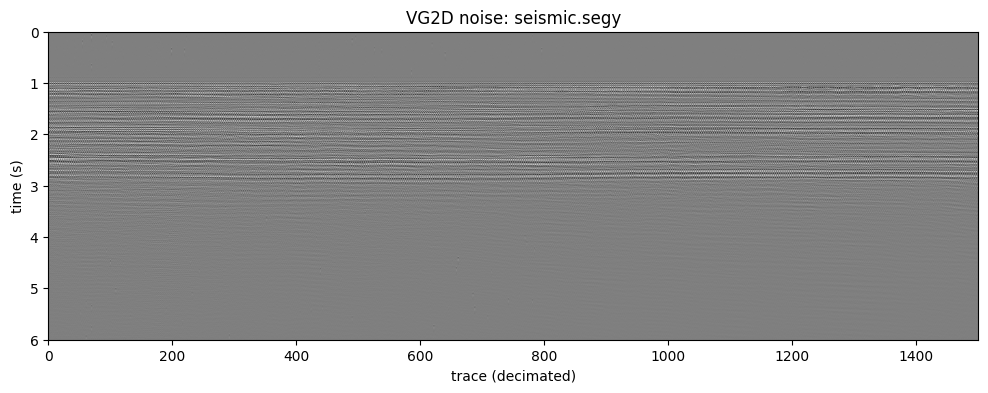


=== F3 signal: seismic_entire_volume.npy | 1104.7 MB | 541501 traces x 255 samples | dt None ms | endian npy | format float64
    ns < 600: the build will up-sample x3
    numpy volume, shape [601, 901, 255] (inline, crossline, samples); dt comes from --dt-override


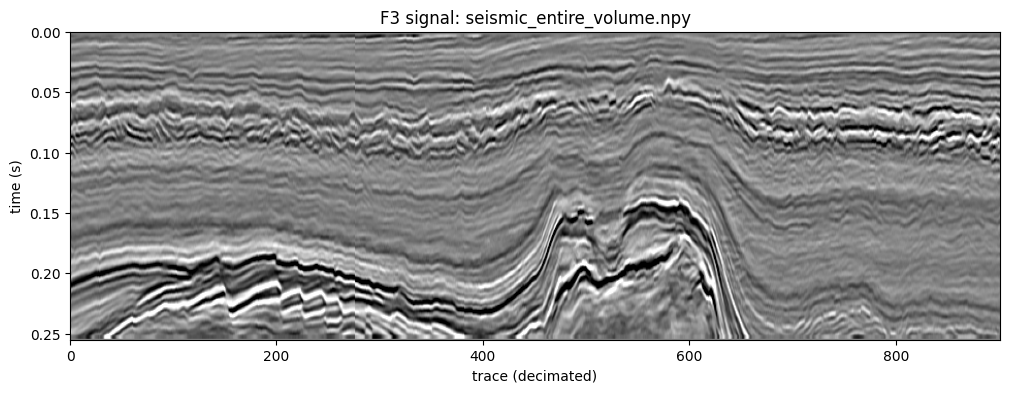


=== STR3D signal: Stratton3D_32bit.sgy | 443.8 MB | 71070 traces x 1501 samples | dt 2.0 ms | endian big | format 1
    line number (5)          min          0  max          0  unique        1
    field record (9)         min          2  max        310  unique      309
    trace in gather (13)     min          0  max          0  unique        1
    energy source pt (17)    min          0  max          0  unique        1
    CDP (21)                 min          1  max        230  unique      230
    offset (37)              min          0  max          0  unique        1
    CDP X (181)              min          0  max          0  unique        1
    CDP Y (185)              min          0  max          0  unique        1
    inline (189)             min          0  max          0  unique        1
    crossline (193)          min          0  max          0  unique        1
    3D check: inline x crossline unique = 1 (should be >= trace count; if inline/crossline are constant, the byte

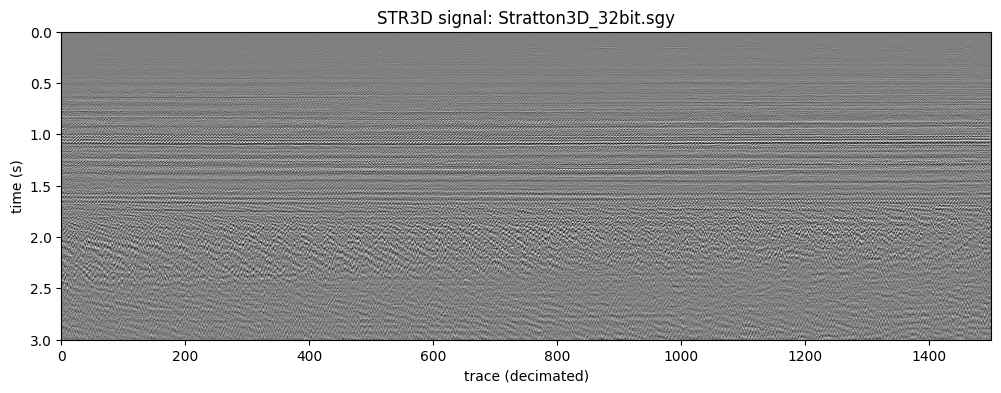

In [3]:
HDR_BYTES = {5: "line number (5)", 9: "field record (9)", 13: "trace in gather (13)", 17: "energy source pt (17)", 21: "CDP (21)",
             37: "offset (37)", 181: "CDP X (181)", 185: "CDP Y (185)", 189: "inline (189)", 193: "crossline (193)"}
INSPECT = {}

def inspect_segy(path, n_img=1500):
    out = dict(path=path, size_mb=round(os.path.getsize(path) / 1e6, 1))
    if path.lower().endswith(".npy"):
        v = np.load(path, mmap_mode="r")
        out.update(endian="npy", ntr=int(np.prod(v.shape[:-1])), ns=int(v.shape[-1]), dt_ms=None, format=str(v.dtype), shape=list(v.shape), headers={})
        out["_img"] = np.asarray(v[v.shape[0] // 2]).astype(np.float32)      # middle inline
        return out
    for e in ("big", "little"):
        try:
            with segyio.open(path, "r", ignore_geometry=True, endian=e) as f:
                f.mmap()
                probe = np.stack([f.trace[int(i)] for i in np.linspace(0, f.tracecount - 1, min(f.tracecount, 64))])
                if not np.isfinite(probe).all() or np.abs(probe).max() > 1e20 or np.abs(probe).max() == 0:
                    continue
                out.update(endian=e, ntr=f.tracecount, ns=len(f.samples), dt_ms=segyio.tools.dt(f, fallback_dt=0) / 1e3,
                           format=int(f.bin[segyio.BinField.Format]))
                hdr = {}
                for b, lab in HDR_BYTES.items():
                    v = np.asarray(f.attributes(b)[:])
                    hdr[lab] = dict(min=int(v.min()), max=int(v.max()), n_unique=int(len(np.unique(v))))
                out["headers"] = hdr
                step = max(1, f.tracecount // n_img)
                out["_img"] = np.stack([f.trace[i] for i in range(0, f.tracecount, step)][:n_img])
            break
        except Exception as ex:
            out["error_" + e] = repr(ex)
    return out

if RUN_INSPECT:
    for code_ in DATASETS_TO_BUILD:
        for role in ("signal", "noise"):
            p = FILES[code_][role]
            if p is None:
                continue
            r = inspect_segy(p); INSPECT[f"{code_}_{role}"] = r
            if "ntr" not in r:
                print(f"{code_} {role}: could not read {p}: {r}"); continue
            print(f"\n=== {code_} {role}: {os.path.basename(p)} | {r['size_mb']} MB | {r['ntr']} traces x {r['ns']} samples | "
                  f"dt {r['dt_ms']} ms | endian {r['endian']} | format {r['format']}")
            if r["ns"] < 600:
                print(f"    ns < 600: the build will up-sample x{int(np.ceil(600 / r['ns']))}")
            if r["endian"] == "npy":
                print(f"    numpy volume, shape {r['shape']} (inline, crossline, samples); dt comes from --dt-override")
            for lab, h in r["headers"].items():
                print(f"    {lab:24s} min {h['min']:>10d}  max {h['max']:>10d}  unique {h['n_unique']:>8d}")
            hd = r["headers"]
            if code_ != "VG2D" and r["endian"] != "npy":
                print("    3D check: inline x crossline unique =", hd["inline (189)"]["n_unique"] * hd["crossline (193)"]["n_unique"],
                      "(should be >= trace count; if inline/crossline are constant, the bytes are elsewhere, e.g. 5/21 or 9/21)")
            img = r.pop("_img"); clip = np.percentile(np.abs(img), 98) + 1e-30
            fig, ax = plt.subplots(figsize=(12, 4))
            ax.imshow(img.T, aspect="auto", cmap="gray", vmin=-clip, vmax=clip,
                      extent=[0, img.shape[0], img.shape[1] * (r["dt_ms"] or 1) / 1e3, 0])
            ax.set_xlabel("trace (decimated)"); ax.set_ylabel("time (s)"); ax.set_title(f"{code_} {role}: {os.path.basename(p)}")
            os.makedirs(OUT_DIR, exist_ok=True); plt.savefig(os.path.join(OUT_DIR, f"inspect_{code_}_{role}.png"), dpi=100, bbox_inches="tight"); plt.show()
    os.makedirs(OUT_DIR, exist_ok=True)
    json.dump(INSPECT, open(os.path.join(OUT_DIR, "inspect_headers.json"), "w"), indent=1, default=str)
else:
    print("inspection skipped (RUN_INSPECT = False)")

In [4]:
SCRIPT = r'''"""new_step2b (EXPLORATION): build signal + noise mixtures from exploration SEG-Y data, same recipe as step2b / notebook 05.

What is the same as the INSTANCE build (notebook 05) and the repo's step2b:
  * per-window, per-channel normalisation: (x - mean) / (std + 1e-12), for the signal and for the noise
  * amplitude factor snr = 10 ** U(-1, 2); optional random shift (nearest-neighbour interp1d, zero fill)
  * stack, divide mixture AND signal by the std of the mixture, NaN -> 0
  * output X_train (mixture) and Y_train (signal only), shape (N, 600, 3), float64, plus 'time'
  * SPLIT BEFORE MIXING with the same sklearn calls and seeds 13 / 20 as step3, rows written train | val | test,
    'split_id' (0, 1, 2) stored for step3_training_1D_presplit.py --presplit
  * the same metadata keys as the INSTANCE file, so notebooks 06, 07 and 08 read it without changes

What is different (every item goes into the deviation log):
  * data: exploration SEG-Y (single component). The 3 input channels are 3 ADJACENT traces
    (neighbouring crosslines / CDPs / receivers), not E, N, Z
  * native sampling interval, 600-sample windows; no resampling to 10 Hz. If a trace has fewer than 600 samples it is
    up-sampled by an integer factor (scipy resample_poly) and the new interval is stored in 'time' and attrs['dt_s']
  * signal = post-stack / migrated traces (not noise-free: a semi-synthetic target)
  * noise, one of three modes:
      prefirstbreak : real noise, the part of raw shot-gather traces before the first break (automatic pick);
                      segments shorter than 600 samples are extended by mirror padding (fraction reported)
      difference    : real noise, unfiltered volume minus filtered volume at the same (inline, crossline)
      synthetic     : band-limited Gaussian noise + low-frequency swell bursts + spikes (seeded)
  * shift defaults to 0 (reflections fill the whole window; the STEAD event shift does not apply)
  * split by SPATIAL BLOCK (groups of inlines for 3D, groups of CDPs for 2D, groups of shots for raw gathers), with
    guard lines/traces at block edges dropped, so neighbouring traces never fall in different splits
  * 'earthquake_name' / 'source_id' hold the signal triplet name / spatial block (names kept for compatibility);
    'source_magnitude', 'event_snr_mean_db', 'p_time_in_window_s' are NaN

Usage:
    python new_step2b_prepare_EXPLORATION_waveforms.py --dataset F3 --signal-segy f3.sgy --noise-mode synthetic \
        --line-byte 189 --trace-byte 193 --out /kaggle/working/exploration_mixtures
"""
import argparse
import json
import os
import time as t
from fractions import Fraction

import h5py
import numpy as np
import segyio
from numpy.random import default_rng
from scipy.interpolate import interp1d
from scipy.ndimage import uniform_filter1d
from scipy.signal import butter, resample_poly, sosfiltfilt
from sklearn.model_selection import train_test_split

WIN = 600
SPLIT_SEED_1, SPLIT_SEED_2, TRAIN_SIZE, TEST_SIZE = 13, 20, 0.6, 0.5   # as step3 / config.py
SPLIT_NAMES = ["train", "val", "test"]
SEED_BASE = {"VG2D": 300, "F3": 400, "STR3D": 500}   # +1 signal, +2 noise, +3 shift, +4 snr, +5 synthetic noise, +6 pools


# ---------------------------------------------------------------------------------------------- SEG-Y reading
def read_segy(path, header_bytes, endian="auto", dt_override=None):
    """All traces as float32 (ntr, ns) and the requested header words. endian 'auto' tries big, then little."""
    tries = ["big", "little"] if endian == "auto" else [endian]
    errors = []
    for e in tries:
        try:
            with segyio.open(path, "r", ignore_geometry=True, endian=e) as f:
                f.mmap()
                ntr, ns = f.tracecount, len(f.samples)
                probe = np.stack([f.trace[int(i)] for i in np.linspace(0, ntr - 1, min(ntr, 64))])
                amax = float(np.nanmax(np.abs(probe))) if np.isfinite(probe).all() else np.inf
                if not np.isfinite(amax) or amax > 1e20 or amax == 0:
                    errors.append(f"endian={e}: implausible sample values (max |x| = {amax:g})"); continue
                dt = dt_override if dt_override else segyio.tools.dt(f, fallback_dt=0) / 1e6
                if not dt or dt <= 0:
                    raise ValueError("sample interval is 0 in the headers: pass --dt-override (seconds)")
                data = f.trace.raw[:].astype(np.float32)
                hdr = {b: np.asarray(f.attributes(int(b))[:]).astype(np.int64) for b in header_bytes if b}
                fmt = int(f.bin[segyio.BinField.Format])
            return dict(data=data, hdr=hdr, dt=float(dt), ns=int(ns), ntr=int(ntr), endian=e, format=fmt, path=path)
        except Exception as ex:   # noqa: BLE001  (report every attempt)
            errors.append(f"endian={e}: {ex!r}")
    raise RuntimeError(f"could not read {path}: " + " | ".join(errors))


def read_npy_volume(path, dt):
    """A 3D volume saved as numpy (n_inline, n_crossline, n_samples), e.g. the F3 facies benchmark volume.
    Returned in the same form as read_segy, with pseudo header words 1 = inline index, 2 = crossline index."""
    assert dt, "a .npy volume has no headers: pass --dt-override (seconds)"
    v = np.load(path, mmap_mode="r")
    assert v.ndim == 3, f"expected (inline, crossline, samples), got shape {v.shape}"
    ni, nx, ns = v.shape
    data = np.empty((ni * nx, ns), dtype=np.float32)
    for i in range(ni):                                  # chunked float64 -> float32, keeps memory low
        data[i * nx:(i + 1) * nx] = v[i]
    il, xl = np.meshgrid(np.arange(ni), np.arange(nx), indexing="ij")
    return dict(data=data, hdr={1: il.ravel().astype(np.int64), 2: xl.ravel().astype(np.int64)}, dt=float(dt), ns=int(ns),
                ntr=int(ni * nx), endian="npy", format=0, path=path)


def resample_to(data, dt_in, dt_out):
    """Resample traces (axis 1) from dt_in to dt_out with a rational polyphase filter."""
    if abs(dt_in - dt_out) < 1e-12:
        return data
    fr = Fraction(dt_in / dt_out).limit_denominator(64)
    return resample_poly(data, fr.numerator, fr.denominator, axis=1).astype(np.float32)


def normalise(x):
    """(600, 3) -> per-channel (x - mean) / (std + 1e-12); None if a channel is flat or not finite (as notebook 05)."""
    sd = np.std(x, axis=0)
    if not np.all(np.isfinite(x)) or np.any(sd < 1e-9):
        return None
    return (x - np.mean(x, axis=0)) / (sd + 1e-12)


def split_blocks(block_ids):
    """Unique block ids -> dict block -> split (0/1/2), same sklearn calls and seeds as step3."""
    u = np.array(sorted(set(int(b) for b in block_ids)))
    if len(u) < 5:
        raise ValueError(f"only {len(u)} spatial blocks: lower --block-size (need at least 5 for a 60/20/20 split)")
    tr, rest = train_test_split(u, train_size=TRAIN_SIZE, random_state=SPLIT_SEED_1)
    va, te = train_test_split(rest, test_size=TEST_SIZE, random_state=SPLIT_SEED_2)
    m = {}
    for k, part in enumerate((tr, va, te)):
        for b in part:
            m[int(b)] = k
    return m


# ---------------------------------------------------------------------------------------------- triplets of adjacent traces
def adjacent_triplets(hdr, ntr, line_byte, trace_byte, block_size, guard, trace_stride):
    """Groups of 3 neighbouring traces along the trace key, inside one line and one spatial block.

    Returns triplets (n, 3) of trace indices, block id per triplet, a readable name per triplet, and a funnel."""
    line = hdr[line_byte] if line_byte else np.zeros(ntr, dtype=np.int64)
    pos = hdr[trace_byte] if trace_byte else np.arange(ntr, dtype=np.int64)
    funnel = [("traces in file", int(ntr))]
    three_d = bool(line_byte)
    # spatial block: groups of `block_size` lines (3D) or of `block_size` trace positions (2D)
    axis_vals = line if three_d else pos
    u = np.unique(axis_vals)
    rank = np.searchsorted(u, axis_vals)
    block = rank // block_size
    within = rank % block_size
    last_block_len = len(u) - (len(u) // block_size) * block_size
    keep_axis = (within >= guard) & (within < block_size - guard)
    # the last (partial) block: guard its own end as well
    is_last = block == (len(u) - 1) // block_size
    if last_block_len:
        keep_axis &= ~(is_last & (within >= last_block_len - guard))
    funnel.append((f"traces kept after guard of {guard} at block edges", int(keep_axis.sum())))

    trip, tblock, names = [], [], []
    for lv in np.unique(line):
        idx = np.where(line == lv)[0]
        idx = idx[np.argsort(pos[idx], kind="stable")]
        p = pos[idx]
        if len(p) < 3:
            continue
        d = np.diff(p)
        step = np.median(d[d > 0]) if np.any(d > 0) else 1
        for j in range(0, len(idx) - 2, trace_stride):
            a, b, c = idx[j], idx[j + 1], idx[j + 2]
            if not (p[j + 1] - p[j] == step and p[j + 2] - p[j + 1] == step):
                continue                                   # gap or duplicate position: not adjacent
            if not (keep_axis[a] and keep_axis[b] and keep_axis[c]):
                continue
            if not (block[a] == block[b] == block[c]):
                continue
            trip.append((a, b, c)); tblock.append(int(block[a]))
            names.append(f"L{int(lv)}_T{int(p[j])}-{int(p[j + 2])}" if three_d else f"T{int(p[j])}-{int(p[j + 2])}")
    funnel.append((f"adjacent triplets (stride {trace_stride})", len(trip)))
    if not trip:
        raise ValueError("no adjacent triplets found: check --line-byte / --trace-byte against the inspection table")
    return np.array(trip), np.array(tblock), np.array(names), funnel


def windows_from_triplets(data, trip, tblock, names, split_of_block, max_pool, time_stride, rng, label):
    """Cut 600-sample windows from triplets; sample at most max_pool * split share; normalise; drop flat windows."""
    ns = data.shape[1]
    starts = np.arange(0, ns - WIN + 1, time_stride)
    if len(starts) == 0:
        raise ValueError(f"{label}: traces have {ns} samples < {WIN}")
    tsplit = np.array([split_of_block[int(b)] for b in tblock])
    shares = (TRAIN_SIZE, (1 - TRAIN_SIZE) * (1 - TEST_SIZE), (1 - TRAIN_SIZE) * TEST_SIZE)
    arr, nm, st, sp, bl = [], [], [], [], []
    n_flat = 0
    stats = {}
    for k in range(3):
        cand_t = np.where(tsplit == k)[0]
        n_cand = len(cand_t) * len(starts)
        n_take = min(n_cand, int(round(max_pool * shares[k] * 1.15)))   # 15 % spare for flat windows
        pick = rng.choice(n_cand, n_take, replace=False) if n_take < n_cand else np.arange(n_cand)
        n_ok = 0
        for q in pick:
            ti, si = cand_t[q // len(starts)], starts[q % len(starts)]
            w = normalise(data[trip[ti], si:si + WIN].T.astype(np.float64))
            if w is None:
                n_flat += 1; continue
            arr.append(w.astype(np.float32)); nm.append(names[ti]); st.append(int(si)); sp.append(k); bl.append(int(tblock[ti]))
            n_ok += 1
            if n_ok >= int(round(max_pool * shares[k])):
                break
        stats[SPLIT_NAMES[k]] = dict(triplets=int(len(cand_t)), candidate_windows=int(n_cand), windows=int(n_ok))
    if n_flat:
        print(f"  {label}: {n_flat} flat / non-finite windows dropped")
    return (np.array(arr), np.array(nm), np.array(st), np.array(sp), np.array(bl),
            dict(starts_per_trace=int(len(starts)), time_stride=int(time_stride), flat_dropped=int(n_flat), per_split=stats))


# ---------------------------------------------------------------------------------------------- brute stack (VG2D: no stack is published)
def nmo(gather, offsets, dt, v_t0, stretch_mute):
    """NMO-correct a gather (ntr, ns) with an RMS velocity per output time v_t0 (ns,). Stretch mute, zero beyond the trace."""
    ns = gather.shape[1]
    t0 = np.arange(ns) * dt
    out = np.zeros_like(gather)
    for i, x in enumerate(offsets):
        tx = np.sqrt(t0 ** 2 + (x / v_t0) ** 2)
        y = np.interp(tx / dt, np.arange(ns), gather[i], right=0.0)
        with np.errstate(divide="ignore", invalid="ignore"):
            stretch = np.where(t0 > 0, tx / t0 - 1.0, np.inf)
        y[stretch > stretch_mute] = 0.0
        out[i] = y
    return out


def velocity_scan(data, cdp, off, dt, cdps, v_grid, stretch_mute, win=11):
    """Semblance summed over a few CDP gathers -> one smooth, non-decreasing RMS velocity function v(t0)."""
    ns = data.shape[1]
    S = np.zeros((len(v_grid), ns))
    box = np.ones(win) / win
    for c in cdps:
        idx = np.where(cdp == c)[0]
        g, x = data[idx], off[idx]
        for k, v in enumerate(v_grid):
            m = nmo(g, x, dt, np.full(ns, v), stretch_mute)
            num = np.convolve(m.sum(0) ** 2, box, mode="same")
            den = np.convolve((m ** 2).sum(0), box, mode="same") * len(idx) + 1e-30
            S[k] += num / den
    t0 = np.arange(ns) * dt
    prior = 1480.0 + 250.0 * t0                         # weak lower bound against water-layer multiples
    S[v_grid[:, None] < prior[None, :]] = 0
    v = v_grid[np.argmax(S, axis=0)].astype(float)
    v[t0 < 0.1] = 1480.0
    k = max(1, int(0.2 / dt)); v = np.convolve(np.pad(v, k, mode="edge"), np.ones(2 * k + 1) / (2 * k + 1), mode="same")[k:-k]
    return np.maximum.accumulate(v), S


def brute_stack(raw, cdp_byte, offset_byte, gain_power, stretch_mute, min_fold_frac, n_scan, v_grid, picks, top_mute_s):
    """Top mute (first break + top_mute_s), t^p gain, CDP sort, automatic velocity scan, NMO, stretch mute, stack."""
    data, dt = raw["data"], raw["dt"]
    t = np.arange(data.shape[1]) * dt
    data = data * (np.maximum(t, dt) ** gain_power)[None, :].astype(np.float32)
    data[np.arange(data.shape[1])[None, :] < (picks + int(round(top_mute_s / dt)))[:, None]] = 0.0   # remove direct arrival / refractions
    cdp = raw["hdr"][cdp_byte]; off = np.abs(raw["hdr"][offset_byte]).astype(float)
    u, fold = np.unique(cdp, return_counts=True)
    keep = u[fold >= min_fold_frac * fold.max()]
    full = u[fold == fold.max()]
    scan_cdps = full[np.linspace(0, len(full) - 1, min(n_scan, len(full))).astype(int)]
    v_t0, _ = velocity_scan(data, cdp, off, dt, scan_cdps, v_grid, stretch_mute)
    order = np.argsort(cdp, kind="stable"); cs = cdp[order]
    lo = np.searchsorted(cs, keep, "left"); hi = np.searchsorted(cs, keep, "right")
    stack = np.zeros((len(keep), data.shape[1]), dtype=np.float32)
    for j, (a, b) in enumerate(zip(lo, hi)):
        idx = order[a:b]
        m = nmo(data[idx], off[idx], dt, v_t0, stretch_mute)
        live = (m != 0).sum(0)
        stack[j] = m.sum(0) / np.maximum(live, 1)
    info = dict(n_cdp_total=int(len(u)), n_cdp_kept=int(len(keep)), max_fold=int(fold.max()), min_fold_kept=int(min_fold_frac * fold.max()),
                gain_power=gain_power, stretch_mute=stretch_mute, top_mute_s=top_mute_s, scan_cdps=[int(c) for c in scan_cdps],
                velocity_t0_s=[round(float(x), 2) for x in t[:: max(1, int(0.5 / dt))]],
                velocity_mps=[round(float(x)) for x in v_t0[:: max(1, int(0.5 / dt))]])
    return stack, keep, v_t0, info


# ---------------------------------------------------------------------------------------------- noise modes
def synthetic_noise(rng, dt, band, swell_band, p_swell, spike_rate):
    """One (600, 3) noise window: band-limited Gaussian (independent per channel) + swell burst (shared) + spikes."""
    fs = 1.0 / dt
    ny = 0.5 * fs
    pad = 200
    lo, hi = band[0], min(band[1], 0.95 * ny)
    g = rng.standard_normal((WIN + 2 * pad, 3))
    g = sosfiltfilt(butter(4, [lo, hi], btype="band", fs=fs, output="sos"), g, axis=0)[pad:-pad]
    g /= g.std(axis=0) + 1e-12
    if rng.random() < p_swell:
        s = rng.standard_normal(WIN + 2 * pad)
        s = sosfiltfilt(butter(2, [swell_band[0], min(swell_band[1], 0.95 * ny)], btype="band", fs=fs, output="sos"), s)[pad:-pad]
        s /= s.std() + 1e-12
        c, w = rng.uniform(0, WIN), rng.uniform(0.1, 0.5) * WIN
        env = np.exp(-0.5 * ((np.arange(WIN) - c) / w) ** 2)
        g += rng.uniform(1, 5) * (env * s)[:, None] * rng.uniform(0.8, 1.2, 3)[None, :]
    n_sp = rng.poisson(spike_rate)
    for _ in range(n_sp):
        g[rng.integers(WIN), rng.integers(3)] += rng.choice([-1, 1]) * rng.uniform(5, 20)
    return normalise(g)


def first_break_picks(x, ref_len, factor, smooth=5):
    """Per trace: first sample where the smoothed |x| exceeds factor * reference level of the first ref_len samples."""
    env = uniform_filter1d(np.abs(x).astype(np.float32), smooth, axis=1)
    floor = 1e-3 * np.median(np.abs(x)) + 1e-30
    ref = np.maximum(np.median(env[:, :ref_len], axis=1), floor)
    above = env > factor * ref[:, None]
    above[:, :ref_len] = False
    pick = np.where(above.any(axis=1), above.argmax(axis=1), x.shape[1])
    return pick


def prefirstbreak_noise(raw, gather_byte, channel_byte, dt_out, block_size, guard, max_pool, ref_len, fb_factor, fb_margin,
                        min_len, rng, shot_split=None):
    """Real noise windows: the samples before the first break, 3 adjacent channels of one shot gather."""
    data = resample_to(raw["data"], raw["dt"], dt_out)
    g = raw["hdr"][gather_byte]
    ch = raw["hdr"][channel_byte] if channel_byte else np.arange(raw["ntr"])
    if channel_byte == 37:
        ch = np.abs(ch)                                       # offset: sort by absolute offset
    picks = first_break_picks(data, ref_len, fb_factor)
    ug = np.unique(g)
    grank = np.searchsorted(ug, g)
    gblock = grank // block_size
    within = grank % block_size
    keep_g = (within >= guard) & (within < block_size - guard)
    if shot_split is None:
        split_of_block = split_blocks(gblock[keep_g])
        block_split = lambda gv, b: split_of_block[b]
    else:                                   # split follows the signal: shot -> split of the CDP block under the shot
        block_split = lambda gv, b: shot_split.get(int(gv), -1)
        keep_g = np.isin(g, [k for k, v in shot_split.items() if v >= 0])
    funnel = [("raw traces", int(raw["ntr"])), ("shot gathers", int(len(ug))), ("traces after guard / split assignment", int(keep_g.sum()))]
    items = []
    for gv in ug:
        idx = np.where((g == gv) & keep_g)[0]
        if len(idx) < 3:
            continue
        idx = idx[np.argsort(ch[idx], kind="stable")]
        for j in range(0, len(idx) - 2, 3):
            tri = idx[j:j + 3]
            L = int(picks[tri].min()) - fb_margin
            if L >= min_len:
                items.append((tri, L, block_split(gv, int(gblock[tri[0]])), f"G{int(gv)}_C{int(ch[tri[0]])}-{int(ch[tri[2]])}"))
    funnel.append((f"channel triplets with >= {min_len} samples before the first break", len(items)))
    if not items:
        raise ValueError("no noise segments found before the first break: check --gather-byte/--channel-byte, --fb-factor, --min-noise-len")
    shares = (TRAIN_SIZE, (1 - TRAIN_SIZE) * (1 - TEST_SIZE), (1 - TRAIN_SIZE) * TEST_SIZE)
    arr, nm, win, sp = [], [], [], []
    n_mirror = 0
    for k in range(3):
        cand = [it for it in items if it[2] == k]
        take = rng.permutation(len(cand))[: int(round(max_pool * shares[k]))]
        for q in take:
            tri, L, b, name = cand[q]
            seg = data[tri, max(0, L - WIN):L].T.astype(np.float64)
            if seg.shape[0] < WIN:
                n_mirror += 1
                seg = np.pad(seg, ((0, WIN - seg.shape[0]), (0, 0)), mode="symmetric")
            w = normalise(seg)
            if w is None:
                continue
            arr.append(w.astype(np.float32)); nm.append(name); win.append(L); sp.append(k)
    lens = np.array([it[1] for it in items])
    info = dict(picks_median_samples=float(np.median(picks)), segment_len_median=float(np.median(lens)),
                segment_len_p10=float(np.percentile(lens, 10)), frac_mirror_padded=float(n_mirror / max(len(arr), 1)),
                fb_factor=fb_factor, fb_ref_len=ref_len, fb_margin=fb_margin, min_len=min_len, funnel=funnel,
                per_split={SPLIT_NAMES[k]: int(np.sum(np.array(sp) == k)) for k in range(3)})
    return np.array(arr), np.array(nm), np.array(win), np.array(sp), info, picks


# ---------------------------------------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--dataset", required=True, choices=sorted(SEED_BASE), help="VG2D, F3 or STR3D")
    ap.add_argument("--signal-segy", default=None,
                    help="post-stack / migrated SEG-Y, or a .npy volume (inline, crossline, samples) with --dt-override; "
                         "not needed with --stack-from-prestack")
    ap.add_argument("--stack-from-prestack", action="store_true",
                    help="signal = brute stack of --noise-segy (raw shot gathers): CDP sort, gain, velocity scan, NMO, stack")
    ap.add_argument("--cdp-byte", type=int, default=21)
    ap.add_argument("--offset-byte", type=int, default=37)
    ap.add_argument("--gain-power", type=float, default=2.0, help="t^p gain before stacking (raw data have no amplitude recovery)")
    ap.add_argument("--stretch-mute", type=float, default=0.5)
    ap.add_argument("--top-mute-s", type=float, default=0.1, help="mute down to first break + this many seconds before stacking")
    ap.add_argument("--min-fold-frac", type=float, default=0.5, help="keep CDPs with at least this fraction of the maximum fold")
    ap.add_argument("--n-scan-cdps", type=int, default=12, help="CDP gathers used for the automatic velocity scan")
    ap.add_argument("--noise-mode", required=True, choices=["prefirstbreak", "difference", "synthetic"])
    ap.add_argument("--noise-segy", default=None, help="raw shot gathers (prefirstbreak) or unfiltered volume (difference)")
    ap.add_argument("--out", required=True)
    ap.add_argument("--out-name", default=None, help="default training_datasets_<DATASET>.hdf5")
    ap.add_argument("--n-mixtures", type=int, default=30000)
    # geometry
    ap.add_argument("--line-byte", type=int, default=0, help="inline header byte for 3D (189); 0 = 2D line")
    ap.add_argument("--trace-byte", type=int, default=0, help="crossline (193) for 3D, CDP (21) for 2D; 0 = trace order")
    ap.add_argument("--block-size", type=int, default=20, help="lines (3D) or trace positions (2D) per spatial block")
    ap.add_argument("--guard", type=int, default=1, help="lines / positions dropped at each block edge")
    ap.add_argument("--trace-stride", type=int, default=3, help="step between triplets along a line (3 = no shared traces)")
    ap.add_argument("--time-stride", type=int, default=300, help="step between window starts in samples")
    ap.add_argument("--max-signal-pool", type=int, default=30000)
    ap.add_argument("--max-noise-pool", type=int, default=10000)
    ap.add_argument("--endian", default="auto", choices=["auto", "big", "little"])
    ap.add_argument("--dt-override", type=float, default=None, help="seconds, if the SEG-Y header has dt = 0")
    ap.add_argument("--resample", type=int, default=0, help="integer up-sampling factor; 0 = automatic (only if ns < 600)")
    ap.add_argument("--shift-range", type=float, nargs=2, default=[0.0, 0.0], help="signal shift range in seconds (default none)")
    # prefirstbreak
    ap.add_argument("--gather-byte", type=int, default=9, help="field record (9) of the raw shot gathers")
    ap.add_argument("--channel-byte", type=int, default=13, help="trace number in gather (13) or offset (37)")
    ap.add_argument("--noise-block-size", type=int, default=20, help="shot gathers per noise block")
    ap.add_argument("--fb-ref-len", type=int, default=25, help="samples at the top of a trace used as the quiet reference")
    ap.add_argument("--fb-factor", type=float, default=5.0)
    ap.add_argument("--fb-margin", type=int, default=10, help="samples kept clear before the pick")
    ap.add_argument("--min-noise-len", type=int, default=200)
    # synthetic
    ap.add_argument("--noise-band-hz", type=float, nargs=2, default=[5.0, 100.0])
    ap.add_argument("--swell-band-hz", type=float, nargs=2, default=[1.0, 6.0])
    ap.add_argument("--p-swell", type=float, default=0.5)
    ap.add_argument("--spike-rate", type=float, default=1.0, help="mean number of spikes per window")
    args = ap.parse_args()

    t0 = t.time()
    sb = SEED_BASE[args.dataset]
    seeds = dict(signal=sb + 1, noise=sb + 2, shift=sb + 3, snr=sb + 4, synthetic=sb + 5, pools=sb + 6)
    os.makedirs(args.out, exist_ok=True)
    out_name = args.out_name or f"training_datasets_{args.dataset}.hdf5"
    rep = dict(dataset=args.dataset, args=vars(args), seeds=seeds)
    rng_pool = default_rng(seeds["pools"])

    # ------------------------------------------------------------------ signal
    raw = None
    if args.stack_from_prestack:
        assert args.noise_segy, "--stack-from-prestack needs --noise-segy (the raw shot gathers)"
        raw = read_segy(args.noise_segy, [args.gather_byte, args.channel_byte, args.cdp_byte, args.offset_byte], args.endian, args.dt_override)
        print(f"raw shot gathers: {raw['ntr']} traces x {raw['ns']} samples, dt {raw['dt'] * 1e3:g} ms, endian {raw['endian']}")
        t1 = t.time()
        fb = first_break_picks(raw["data"], args.fb_ref_len, args.fb_factor)
        stack, stack_cdp, v_t0, st_info = brute_stack(raw, args.cdp_byte, args.offset_byte, args.gain_power, args.stretch_mute,
                                                      args.min_fold_frac, args.n_scan_cdps, np.arange(1450.0, 4501.0, 50.0),
                                                      fb, args.top_mute_s)
        print(f"  brute stack: {st_info['n_cdp_kept']} CDPs (max fold {st_info['max_fold']}), {t.time() - t1:.0f} s")
        print("  velocity function (t0 s -> m/s):", list(zip(st_info["velocity_t0_s"], st_info["velocity_mps"])))
        np.save(os.path.join(args.out, f"brute_stack_{args.dataset}.npy"), stack)
        np.save(os.path.join(args.out, f"brute_stack_velocity_{args.dataset}.npy"), v_t0)
        rep["brute_stack"] = st_info
        args.line_byte, args.trace_byte = 0, args.cdp_byte
        sig = dict(data=stack, hdr={args.cdp_byte: stack_cdp.astype(np.int64)}, dt=raw["dt"], ns=raw["ns"], ntr=int(len(stack_cdp)),
                   endian=raw["endian"], format=raw["format"], path=args.noise_segy + " (brute stack)")
        args.signal_segy = sig["path"]
    else:
        assert args.signal_segy, "--signal-segy is required unless --stack-from-prestack is used"
        if args.signal_segy.lower().endswith(".npy"):
            sig = read_npy_volume(args.signal_segy, args.dt_override)
            args.line_byte, args.trace_byte = 1, 2           # pseudo header words: inline / crossline index
        else:
            sig = read_segy(args.signal_segy, [args.line_byte, args.trace_byte], args.endian, args.dt_override)
    print(f"signal: {sig['ntr']} traces x {sig['ns']} samples, dt {sig['dt'] * 1e3:g} ms, endian {sig['endian']}, format {sig['format']}")
    r = args.resample if args.resample else (int(np.ceil(WIN / sig["ns"])) if sig["ns"] < WIN else 1)
    data = resample_poly(sig["data"], r, 1, axis=1).astype(np.float32) if r > 1 else sig["data"]
    dt = sig["dt"] / r
    if r > 1:
        print(f"  up-sampled x{r}: {sig['ns']} -> {data.shape[1]} samples, dt {dt * 1e3:g} ms")
    rep["signal_file"] = dict(path=args.signal_segy, ntr=sig["ntr"], ns=sig["ns"], dt_s=sig["dt"], endian=sig["endian"], format=sig["format"],
                              resample_factor=r, ns_used=int(data.shape[1]), dt_used_s=dt)
    trip, tblock, tnames, funnel = adjacent_triplets(sig["hdr"], sig["ntr"], args.line_byte, args.trace_byte, args.block_size, args.guard,
                                                     args.trace_stride)
    split_of_block = split_blocks(tblock)
    s_arr, s_name, s_start, s_split, s_block, s_info = windows_from_triplets(data, trip, tblock, tnames, split_of_block, args.max_signal_pool,
                                                                              args.time_stride, rng_pool, "signal")
    funnel.append(("signal windows in the pool", int(len(s_arr))))
    for k, v in funnel:
        print(f"  {k:60s} {v}")
    rep["signal_funnel"] = funnel; rep["signal_pool"] = s_info
    rep["signal_blocks"] = {SPLIT_NAMES[k]: sorted(b for b, s in split_of_block.items() if s == k) for k in range(3)}

    # ------------------------------------------------------------------ noise
    if args.noise_mode == "synthetic":
        n_arr, n_name, n_win, n_split = [], [], [], []
        shares = (TRAIN_SIZE, (1 - TRAIN_SIZE) * (1 - TEST_SIZE), (1 - TRAIN_SIZE) * TEST_SIZE)
        for k in range(3):
            rng_k = default_rng(seeds["synthetic"] + 10 * k)                     # independent noise per split
            for i in range(int(round(args.max_noise_pool * shares[k]))):
                w = synthetic_noise(rng_k, dt, args.noise_band_hz, args.swell_band_hz, args.p_swell, args.spike_rate)
                n_arr.append(w.astype(np.float32)); n_name.append(f"synthetic_{SPLIT_NAMES[k]}_{i}"); n_win.append(0); n_split.append(k)
        n_arr, n_name, n_win, n_split = map(np.array, (n_arr, n_name, n_win, n_split))
        rep["noise_pool"] = dict(mode="synthetic", band_hz=args.noise_band_hz, swell_band_hz=args.swell_band_hz, p_swell=args.p_swell,
                                 spike_rate=args.spike_rate, per_split={SPLIT_NAMES[k]: int((n_split == k).sum()) for k in range(3)})
    elif args.noise_mode == "difference":
        assert args.noise_segy, "--noise-mode difference needs --noise-segy (the unfiltered volume)"
        raw = read_segy(args.noise_segy, [args.line_byte, args.trace_byte], args.endian, args.dt_override)
        assert raw["ns"] == sig["ns"] and abs(raw["dt"] - sig["dt"]) < 1e-9, "unfiltered and filtered volumes differ in ns or dt"
        key = lambda d, i: (int(d["hdr"][args.line_byte][i]) if args.line_byte else 0, int(d["hdr"][args.trace_byte][i]) if args.trace_byte else i)
        where = {key(raw, i): i for i in range(raw["ntr"])}
        match = np.array([where.get(key(sig, i), -1) for i in range(sig["ntr"])])
        print(f"  difference mode: {int((match >= 0).sum())} of {sig['ntr']} filtered traces matched in the unfiltered volume")
        assert (match >= 0).mean() > 0.9, "fewer than 90 % of traces match by (line, trace): check the header bytes"
        diff = np.zeros_like(sig["data"]); ok = match >= 0
        diff[ok] = raw["data"][match[ok]] - sig["data"][ok]
        rel = float(np.std(diff[ok]) / (np.std(sig["data"][ok]) + 1e-30))
        print(f"  std(unfiltered - filtered) / std(filtered) = {rel:.3f}")
        assert rel > 1e-3, "the two volumes are (almost) identical: no noise to extract"
        diff = resample_poly(diff, r, 1, axis=1).astype(np.float32) if r > 1 else diff
        n_arr, n_name, n_win, n_split, n_block, n_info = windows_from_triplets(diff, trip, tblock, tnames, split_of_block, args.max_noise_pool,
                                                                                args.time_stride, rng_pool, "noise")
        n_name = np.array([f"diff_{a}" for a in n_name])
        rep["noise_pool"] = dict(mode="difference", noise_file=args.noise_segy, rel_std=rel, **n_info)
    else:   # prefirstbreak
        assert args.noise_segy, "--noise-mode prefirstbreak needs --noise-segy (the raw shot gathers)"
        shot_split = None
        if raw is None:
            raw = read_segy(args.noise_segy, [args.gather_byte, args.channel_byte], args.endian, args.dt_override)
        else:
            # same raw file as the signal: give each shot the split of the CDP block under it (median CDP of the shot),
            # so train / val / test signal and noise come from different parts of the line
            u_cdp = np.unique(sig["hdr"][args.cdp_byte])
            shot_split = {}
            for gv in np.unique(raw["hdr"][args.gather_byte]):
                mc = np.median(raw["hdr"][args.cdp_byte][raw["hdr"][args.gather_byte] == gv])
                r_ = int(np.clip(np.searchsorted(u_cdp, mc), 0, len(u_cdp) - 1))
                shot_split[int(gv)] = split_of_block.get(r_ // args.block_size, -1)
        print(f"noise: {raw['ntr']} raw traces x {raw['ns']} samples, dt {raw['dt'] * 1e3:g} ms, endian {raw['endian']}")
        n_arr, n_name, n_win, n_split, n_info, picks = prefirstbreak_noise(
            raw, args.gather_byte, args.channel_byte, dt, args.noise_block_size, args.guard, args.max_noise_pool, args.fb_ref_len,
            args.fb_factor, args.fb_margin, args.min_noise_len, rng_pool, shot_split=shot_split)
        np.save(os.path.join(args.out, f"fb_picks_{args.dataset}.npy"), picks)
        for k, v in n_info["funnel"]:
            print(f"  {k:60s} {v}")
        rep["noise_pool"] = dict(mode="prefirstbreak", noise_file=args.noise_segy, raw_dt_s=raw["dt"], raw_ns=raw["ns"], raw_endian=raw["endian"], **n_info)
    print(f"noise pool ready: {len(n_arr)} windows, per split {[int((n_split == k).sum()) for k in range(3)]}")

    for k in range(3):
        assert (s_split == k).any(), f"no signal windows in split {SPLIT_NAMES[k]}"
        assert (n_split == k).any(), f"no noise windows in split {SPLIT_NAMES[k]}"
    for a_, b_ in ((0, 1), (0, 2), (1, 2)):                 # hard guarantee: nothing shared between splits
        assert not (set(s_name[s_split == a_]) & set(s_name[s_split == b_])), "signal triplet shared between splits"
        assert not (set(n_name[n_split == a_]) & set(n_name[n_split == b_])), "noise triplet shared between splits"
        assert not (set(s_block[s_split == a_]) & set(s_block[s_split == b_])), "spatial block shared between splits"

    # ------------------------------------------------------------------ mixtures (same code path as notebook 05)
    N = args.n_mixtures
    n_split_rows = [int(round(N * TRAIN_SIZE)), 0, 0]
    n_split_rows[1] = int(round(N * (1 - TRAIN_SIZE) * (1 - TEST_SIZE))); n_split_rows[2] = N - n_split_rows[0] - n_split_rows[1]
    split_id = np.concatenate([np.full(n, k, dtype=np.int8) for k, n in enumerate(n_split_rows)])
    shift = default_rng(seeds["shift"]).uniform(args.shift_range[0], args.shift_range[1], N)
    snr = 10 ** default_rng(seeds["snr"]).uniform(-1, 2, N)
    s_idx = np.empty(N, dtype=int); n_idx = np.empty(N, dtype=int)
    for k in range(3):
        rows = np.where(split_id == k)[0]
        pool_s = np.where(s_split == k)[0]; pool_n = np.where(n_split == k)[0]
        s_idx[rows] = pool_s[default_rng(seeds["signal"] + 10 * k).choice(len(pool_s), len(rows))]
        n_idx[rows] = pool_n[default_rng(seeds["noise"] + 10 * k).choice(len(pool_n), len(rows))]

    out_path = os.path.join(args.out, out_name)
    time_new = np.arange(WIN) * dt
    energy_frac = np.zeros(N); n_nan = 0
    with h5py.File(out_path, "w") as f:
        dX = f.create_dataset("X_train", shape=(N, WIN, 3), dtype="f8", compression="gzip", chunks=(min(1000, N), WIN, 3))
        dY = f.create_dataset("Y_train", shape=(N, WIN, 3), dtype="f8", compression="gzip", chunks=(min(1000, N), WIN, 3))
        f.create_dataset("time", data=time_new)
        B = 1000
        for b0 in range(0, N, B):
            Xb, Yb = [], []
            for i in range(b0, min(b0 + B, N)):
                q = s_arr[s_idx[i]].astype(np.float64); nz = n_arr[n_idx[i]].astype(np.float64)
                energy_before = np.sum(q ** 2)
                if shift[i] != 0:
                    q_sh = interp1d(time_new + shift[i], q, axis=0, kind="nearest", bounds_error=False, fill_value=0.0)(time_new)
                else:
                    q_sh = q
                energy_frac[i] = np.sum(q_sh ** 2) / energy_before
                qs = snr[i] * q_sh
                stacked = qs + nz
                sd = np.std(stacked, axis=0)
                Xb.append(stacked / sd); Yb.append(qs / sd)
            Xb = np.array(Xb); Yb = np.array(Yb)
            n_nan += int(np.isnan(Xb).sum() + np.isnan(Yb).sum())
            Xb[np.isnan(Xb)] = 0; Yb[np.isnan(Yb)] = 0
            dX[b0:b0 + len(Xb)] = Xb; dY[b0:b0 + len(Yb)] = Yb
            print(f"  mixtures {b0 + len(Xb)} / {N}", flush=True)

        def wmeta(key, val):
            val = np.asarray(val)
            if val.dtype.kind in ("U", "O", "S"):
                f.create_dataset(key, data=val.astype(str).astype(object), dtype=h5py.string_dtype())
            else:
                f.create_dataset(key, data=val)
        nan = np.full(N, np.nan)
        wmeta("split_id", split_id)
        # INSTANCE-compatible keys (read by notebooks 06 / 07 / 08)
        wmeta("earthquake_name", s_name[s_idx]); wmeta("source_id", s_block[s_idx])
        wmeta("event_snr_mean_db", nan); wmeta("station_channels", np.full(N, f"{args.dataset}:3 adjacent traces"))
        wmeta("source_magnitude", nan)
        wmeta("noise_name", n_name[n_idx]); wmeta("noise_window", n_win[n_idx])
        wmeta("shift", shift); wmeta("snr", snr); wmeta("quake_energy_frac", energy_frac)
        wmeta("p_time_in_window_s", nan)
        # exploration-specific keys
        wmeta("signal_start_sample", s_start[s_idx]); wmeta("signal_block", s_block[s_idx])
        for k, v in dict(dataset=args.dataset, n_train=n_split_rows[0], n_val=n_split_rows[1], n_test=n_split_rows[2],
                         dt_s=dt, dt_original_s=sig["dt"], resample_factor=r, ns_original=sig["ns"], noise_mode=args.noise_mode,
                         split_seed_1=SPLIT_SEED_1, split_seed_2=SPLIT_SEED_2, block_size=args.block_size, guard=args.guard,
                         component_order="3 adjacent traces along the trace key (not E,N,Z)",
                         signal_file=os.path.basename(args.signal_segy), noise_file=os.path.basename(args.noise_segy or ""),
                         signal_is_brute_stack=bool(args.stack_from_prestack),
                         units="normalised (per window and channel), then divided by the std of the mixture").items():
            f.attrs[k] = v

    # ------------------------------------------------------------------ report
    def use_stats(idx, split_k, pool_split):
        rows = split_id == split_k
        u, c = np.unique(idx[rows], return_counts=True)
        return dict(pool=int((pool_split == split_k).sum()), drawn_unique=int(len(u)), max_uses=int(c.max()),
                    mean_uses=float(rows.sum() / max((pool_split == split_k).sum(), 1)))
    rep["mixtures"] = dict(N=int(N), per_split=dict(zip(SPLIT_NAMES, n_split_rows)), nan_replaced_by_zero=n_nan,
                           frac_energy_left_lt_1pct=float((energy_frac < 0.01).mean()),
                           signal_use={SPLIT_NAMES[k]: use_stats(s_idx, k, s_split) for k in range(3)},
                           noise_use={SPLIT_NAMES[k]: use_stats(n_idx, k, n_split) for k in range(3)})
    rep["output"] = out_path
    rep["output_bytes"] = os.path.getsize(out_path)
    rep["seconds"] = t.time() - t0
    with open(os.path.join(args.out, f"build_report_{args.dataset}.json"), "w") as fj:
        json.dump(rep, fj, indent=1, default=str)
    print(json.dumps(rep["mixtures"], indent=1))
    print("saved:", out_path, f"({rep['output_bytes'] / 1e6:.0f} MB)")


if __name__ == "__main__":
    main()
'''

SCRIPT_PATH = os.path.join(WORK, 'new_step2b_prepare_EXPLORATION_waveforms.py')
open(SCRIPT_PATH, 'w').write(SCRIPT)
SCRIPT_SHA = hashlib.sha256(SCRIPT.encode()).hexdigest()[:16]
print('script sha256[:16]:', SCRIPT_SHA)

script sha256[:16]: 1e375b728115735e


In [5]:
STATUS = {}
if RUN_BUILD:
    for code_ in DATASETS_TO_BUILD:
        c, fs = DATASETS[code_], FILES[code_]
        from_prestack = "--stack-from-prestack" in c["args"]
        if from_prestack and fs["noise"] is None:
            STATUS[code_] = "skipped: raw shot gathers not found"; print(code_, STATUS[code_]); continue
        if fs["signal"] is None and not from_prestack:
            STATUS[code_] = "skipped: signal file not found"; print(code_, STATUS[code_]); continue
        mode = c["noise_mode"]
        if mode in ("prefirstbreak", "difference") and fs["noise"] is None:
            if mode == "prefirstbreak":
                STATUS[code_] = "skipped: raw shot gathers not found (needed for real noise)"; print(code_, STATUS[code_]); continue
            print(f"{code_}: unfiltered volume not found -> FALLBACK to synthetic noise (recorded in the summary)")
            mode = "synthetic"
        cmd = [sys.executable, SCRIPT_PATH, "--dataset", code_, "--noise-mode", mode, "--out", OUT_DIR, "--n-mixtures", str(N_MIXTURES), *c["args"]]
        if not from_prestack:
            cmd += ["--signal-segy", fs["signal"]]
        if mode != "synthetic":
            cmd += ["--noise-segy", fs["noise"]]
        print("\n" + "=" * 100 + f"\n{code_}: " + " ".join(cmd)); t0 = time.time()
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        for line in p.stdout:
            if line.startswith("  mixtures") and not line.split()[1].endswith("0000"): continue     # keep the log short
            print(line, end="")
        p.wait()
        STATUS[code_] = "ok" if p.returncode == 0 else f"FAILED (return code {p.returncode})"
        DATASETS[code_]["noise_mode_used"] = mode
        print(f"{code_}: {STATUS[code_]} | {time.time() - t0:.0f} s")
    print("\nbuild status:", STATUS)
    assert any(v == "ok" for v in STATUS.values()), "no dataset was built: read the messages above"
else:
    print("build skipped (RUN_BUILD = False)")


VG2D: /usr/bin/python3 /kaggle/working/new_step2b_prepare_EXPLORATION_waveforms.py --dataset VG2D --noise-mode prefirstbreak --out /kaggle/working/exploration_mixtures --n-mixtures 30000 --stack-from-prestack --cdp-byte 21 --offset-byte 37 --block-size 100 --guard 2 --gather-byte 9 --channel-byte 13 --min-noise-len 300 --noise-segy /kaggle/temp/raw/seismic.segy
raw shot gathers: 120120 traces x 1500 samples, dt 4 ms, endian big
  brute stack: 2026 CDPs (max fold 60), 15 s
  velocity function (t0 s -> m/s): [(0.0, 1476), (0.5, 2245), (1.0, 2245), (1.5, 2245), (2.0, 2245), (2.5, 2288), (3.0, 2345), (3.5, 2391), (4.0, 2505), (4.5, 2707), (5.0, 2964), (5.5, 3179)]
signal: 2026 traces x 1500 samples, dt 4 ms, endian big, format 1
  traces in file                                               2026
  traces kept after guard of 2 at block edges                  1942
  adjacent triplets (stride 3)                                 633
  signal windows in the pool                                 


VG2D  (2D marine, Mobil AVO Viking Graben line 12)
signal funnel:
  traces in file                                              2026
  traces kept after guard of 2 at block edges                 1942
  adjacent triplets (stride 3)                                633
  signal windows in the pool                                  2532
noise pool: {'mode': 'prefirstbreak', 'noise_file': '/kaggle/temp/raw/seismic.segy', 'raw_dt_s': 0.004, 'raw_ns': 1500, 'raw_endian': 'big', 'picks_median_samples': 298.0, 'segment_len_median': 385.0, 'segment_len_p10': 319.0, 'frac_mirror_padded': 1.0, 'fb_factor': 5.0, 'fb_ref_len': 25, 'fb_margin': 10, 'min_len': 300, 'per_split': {'train': 6000, 'val': 2000, 'test': 2000}}
signal reuse: {'train': {'pool': 1404, 'drawn_unique': 1404, 'max_uses': 29, 'mean_uses': 12.820512820512821}, 'val': {'pool': 500, 'drawn_unique': 500, 'max_uses': 24, 'mean_uses': 12.0}, 'test': {'pool': 628, 'drawn_unique': 628, 'max_uses': 20, 'mean_uses': 9.554140127388536}}
noise

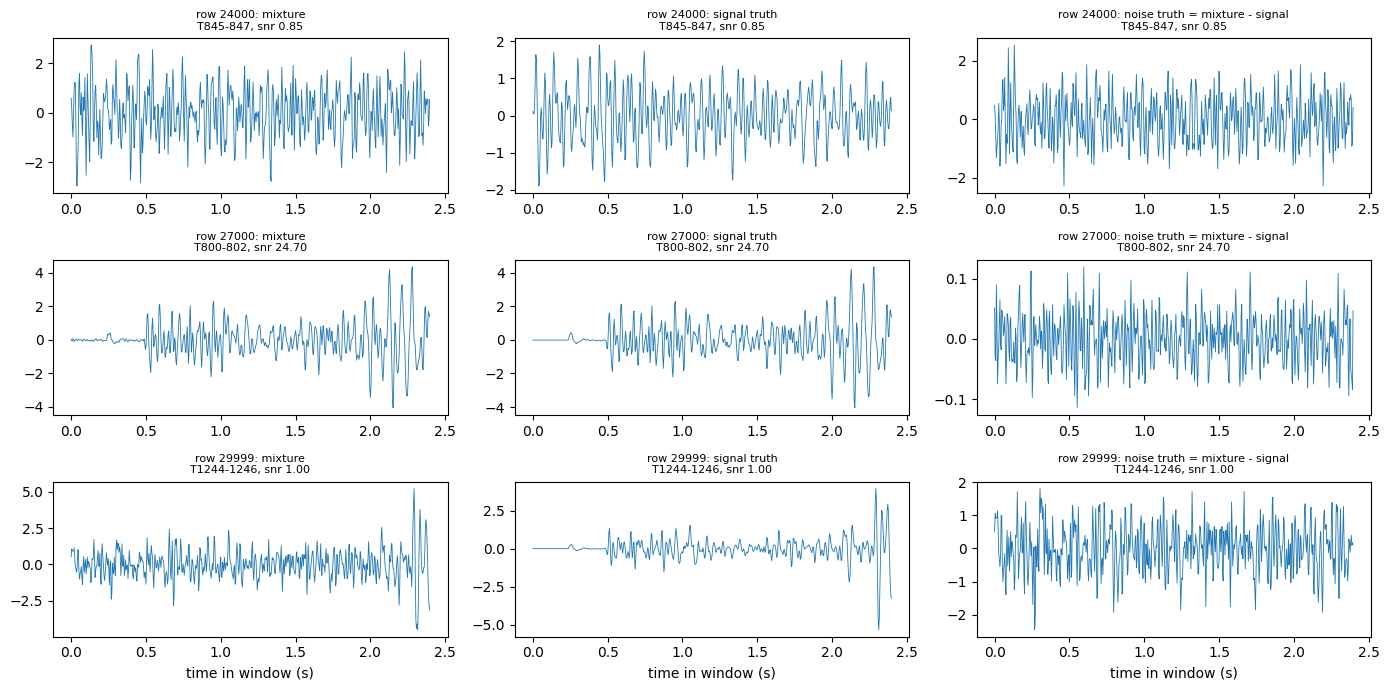

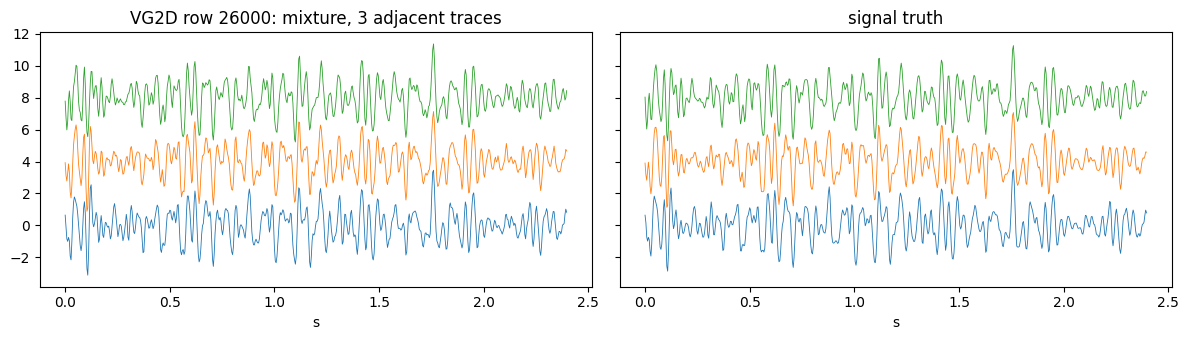

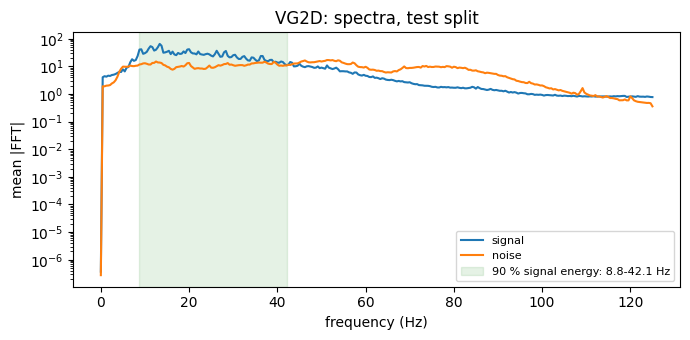

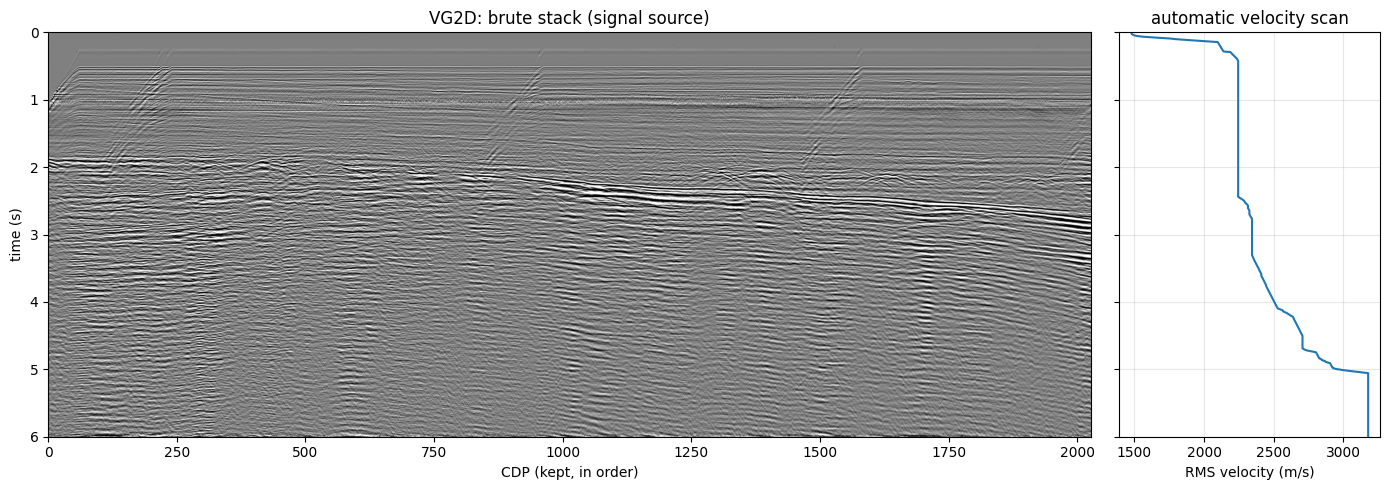

brute stack: {'n_cdp_total': 2142, 'n_cdp_kept': 2026, 'max_fold': 60, 'min_fold_kept': 30, 'gain_power': 2.0, 'stretch_mute': 0.5, 'top_mute_s': 0.1, 'velocity_t0_s': [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5], 'velocity_mps': [1476, 2245, 2245, 2245, 2245, 2288, 2345, 2391, 2505, 2707, 2964, 3179]}


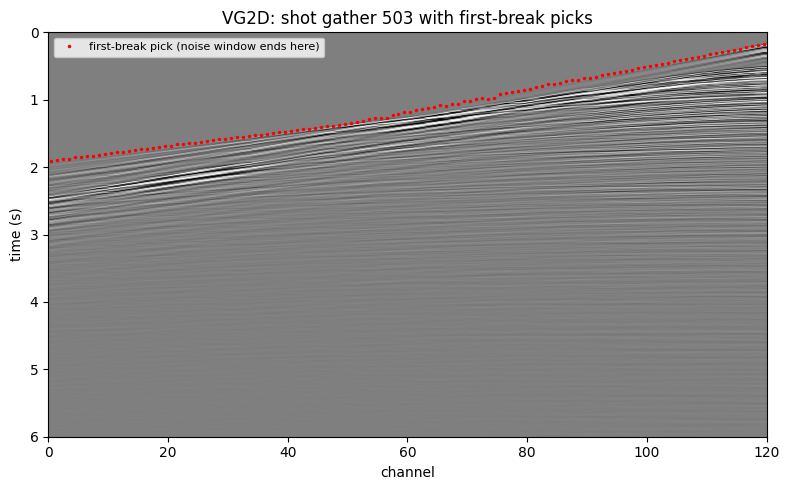

mirror-padded noise windows (pre-first-break segment < 600 samples): 100.0 %

F3  (3D marine, F3 Netherlands (facies benchmark volume, Zenodo 3755060))
signal funnel:
  traces in file                                              541501
  traces kept after guard of 1 at block edges                 486540
  adjacent triplets (stride 3)                                162000
  signal windows in the pool                                  30000
noise pool: {'mode': 'synthetic', 'band_hz': [5.0, 100.0], 'swell_band_hz': [1.0, 6.0], 'p_swell': 0.5, 'spike_rate': 1.0, 'per_split': {'train': 6000, 'val': 2000, 'test': 2000}}
signal reuse: {'train': {'pool': 18000, 'drawn_unique': 11325, 'max_uses': 7, 'mean_uses': 1.0}, 'val': {'pool': 6000, 'drawn_unique': 3876, 'max_uses': 6, 'mean_uses': 1.0}, 'test': {'pool': 6000, 'drawn_unique': 3799, 'max_uses': 6, 'mean_uses': 1.0}}
noise reuse: {'train': {'pool': 6000, 'drawn_unique': 5685, 'max_uses': 11, 'mean_uses': 3.0}, 'val': {'pool': 2000, 'drawn_

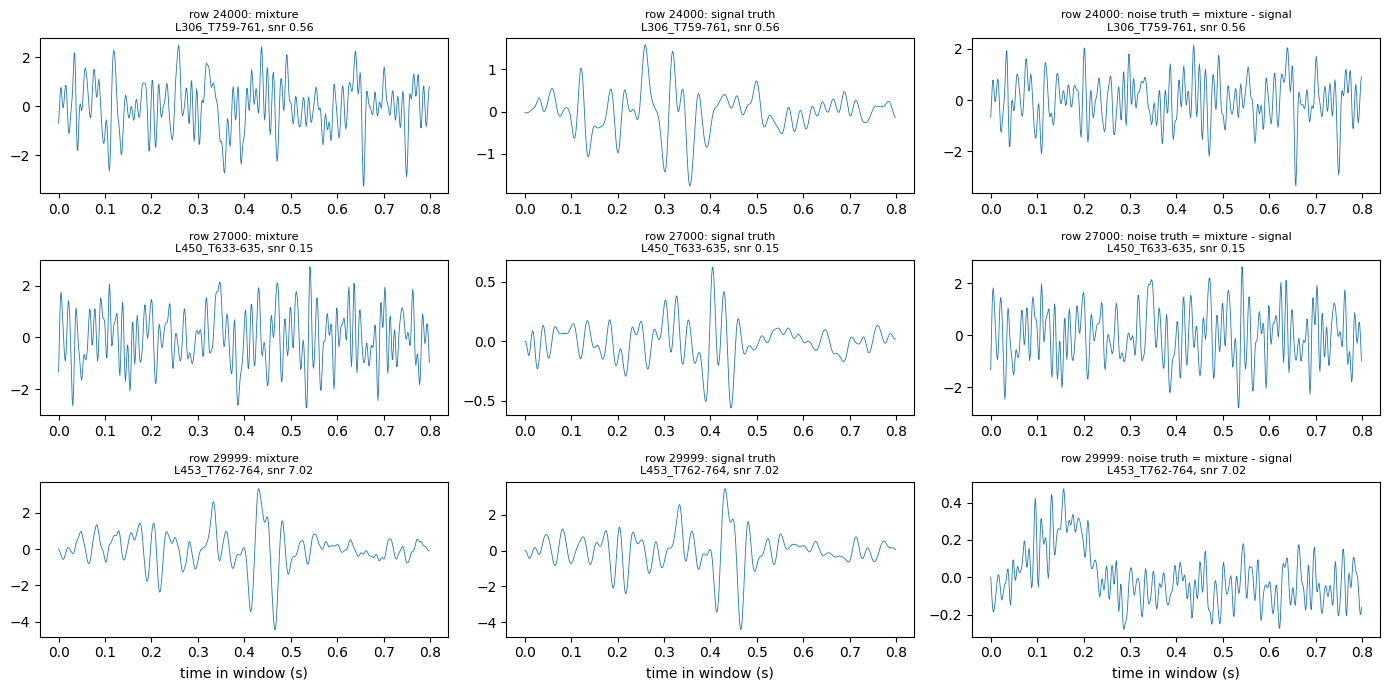

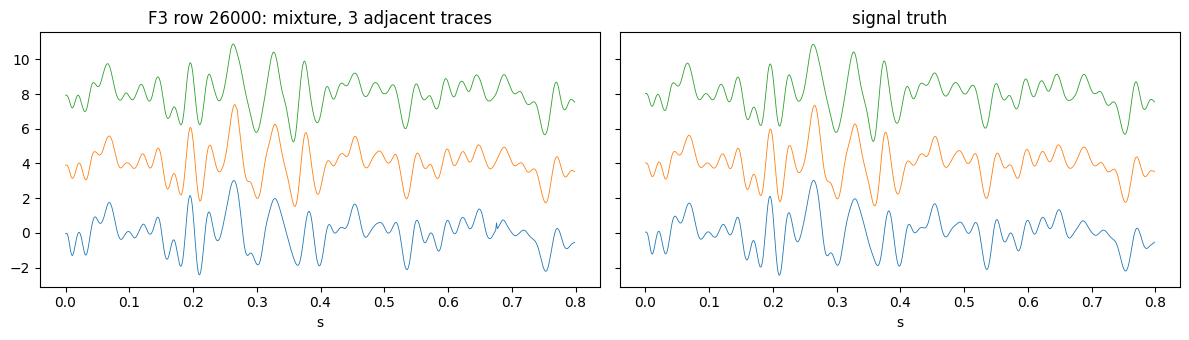

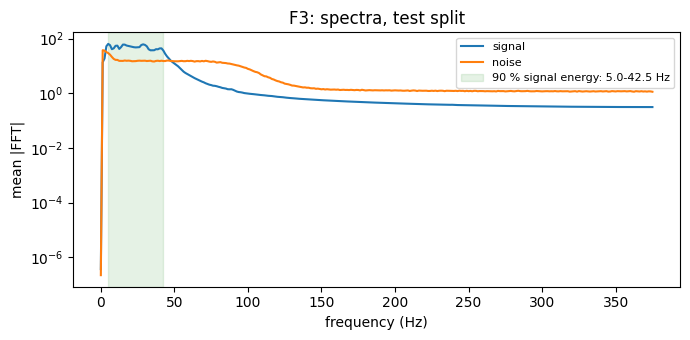


STR3D  (3D land, Stratton 3D (Bureau of Economic Geology, UT Austin))
signal funnel:
  traces in file                                              71070
  traces kept after guard of 1 at block edges                 63710
  adjacent triplets (stride 3)                                21052
  signal windows in the pool                                  30000
noise pool: {'mode': 'synthetic', 'band_hz': [5.0, 100.0], 'swell_band_hz': [1.0, 6.0], 'p_swell': 0.5, 'spike_rate': 1.0, 'per_split': {'train': 6000, 'val': 2000, 'test': 2000}}
signal reuse: {'train': {'pool': 18000, 'drawn_unique': 11341, 'max_uses': 7, 'mean_uses': 1.0}, 'val': {'pool': 6000, 'drawn_unique': 3820, 'max_uses': 6, 'mean_uses': 1.0}, 'test': {'pool': 6000, 'drawn_unique': 3837, 'max_uses': 6, 'mean_uses': 1.0}}
noise reuse: {'train': {'pool': 6000, 'drawn_unique': 5706, 'max_uses': 10, 'mean_uses': 3.0}, 'val': {'pool': 2000, 'drawn_unique': 1909, 'max_uses': 10, 'mean_uses': 3.0}, 'test': {'pool': 2000, 'drawn_uniq

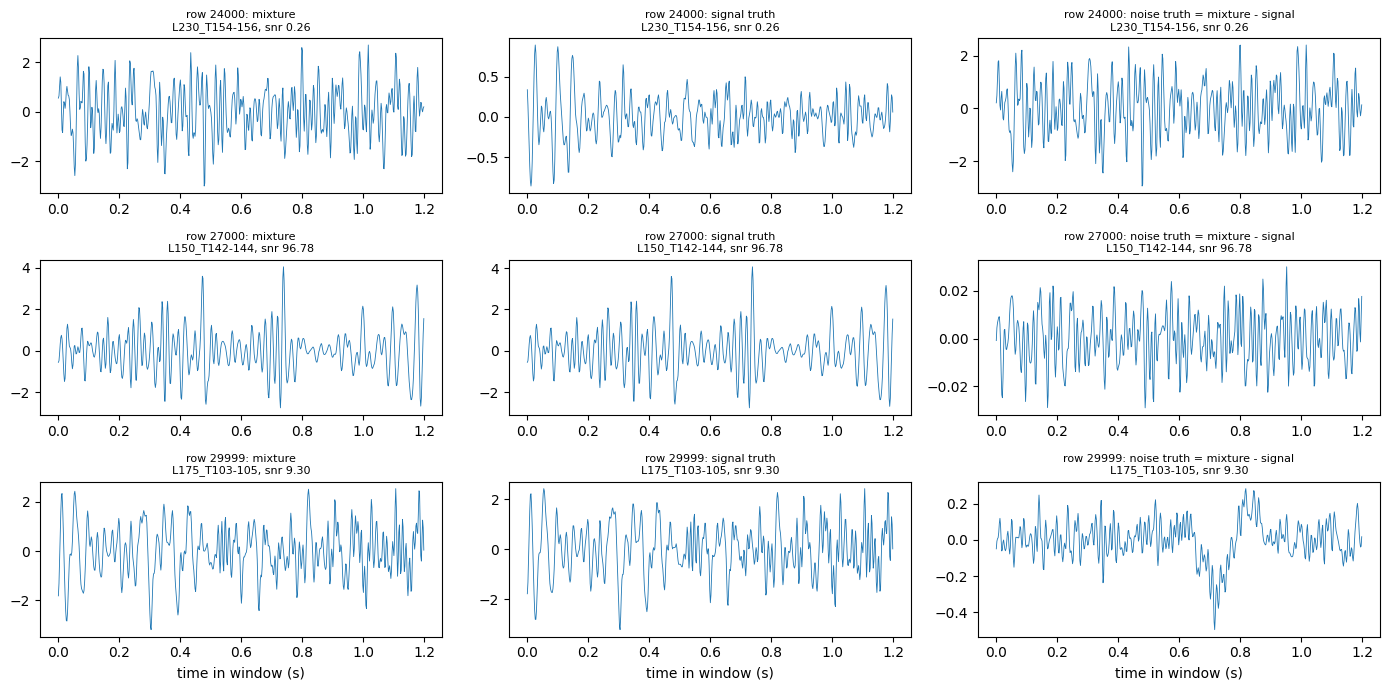

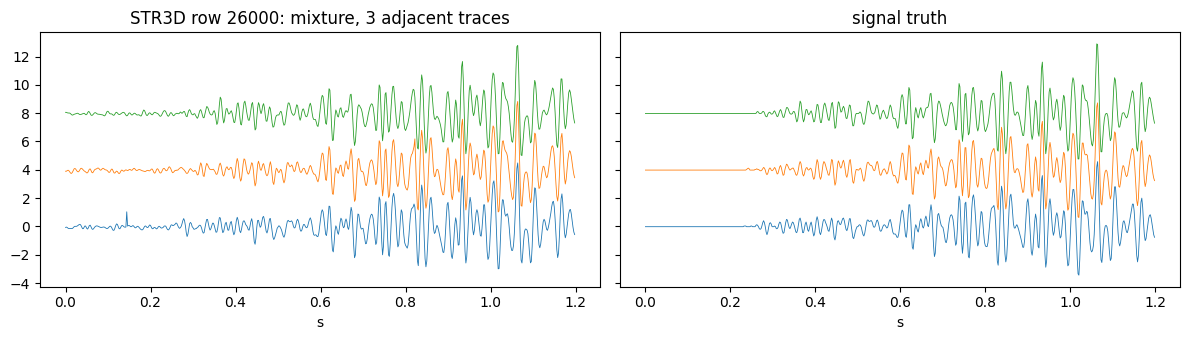

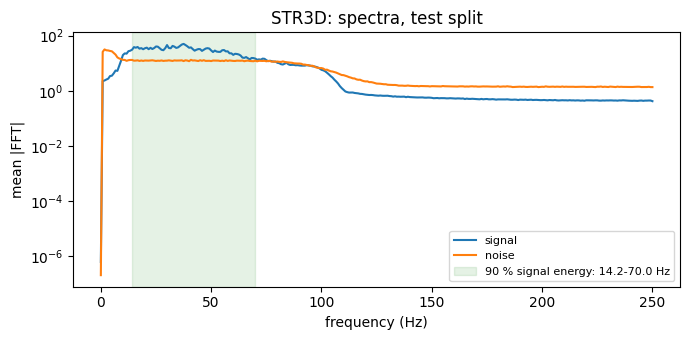

In [6]:
# Checks and figures, one dataset at a time
import h5py
CHECKS = {}

def spectrum(a, dt):
    A = np.abs(np.fft.rfft(a, axis=1)).mean(axis=(0, 2)); return np.fft.rfftfreq(a.shape[1], dt), A

def band_90(fr, A):
    e = np.cumsum(A ** 2); e /= e[-1]
    return float(fr[np.searchsorted(e, 0.05)]), float(fr[np.searchsorted(e, 0.95)])

for code_ in [k for k, v in STATUS.items() if v == "ok"]:
    path = os.path.join(OUT_DIR, f"training_datasets_{code_}.hdf5")
    rep = json.load(open(os.path.join(OUT_DIR, f"build_report_{code_}.json")))
    print("\n" + "=" * 100 + f"\n{code_}  ({DATASETS[code_]['category']}, {DATASETS[code_]['survey']})")
    print("signal funnel:"); [print(f"  {k:60s}{v}") for k, v in rep["signal_funnel"]]
    print("noise pool:", {k: v for k, v in rep["noise_pool"].items() if k not in ("funnel", "per_split_detail")})
    print("signal reuse:", rep["mixtures"]["signal_use"]); print("noise reuse:", rep["mixtures"]["noise_use"])
    with h5py.File(path, "r") as f:
        X, Y = f["X_train"], f["Y_train"]; dt = float(f.attrs["dt_s"])
        print("shapes", X.shape, Y.shape, X.dtype, "| dt", dt, "s | keys:", sorted(f.keys()))
        assert X.shape == Y.shape and X.shape[1:] == (600, 3) and X.dtype == np.float64
        sp = f["split_id"][:]; blk = f["source_id"][:]; nn = f["noise_name"][:].astype(str); sn = f["earthquake_name"][:].astype(str)
        assert (np.diff(sp.astype(int)) >= 0).all(), "rows must be train | val | test"
        for a, b in ((0, 1), (0, 2), (1, 2)):
            assert not (set(blk[sp == a]) & set(blk[sp == b])), "spatial block shared between splits"
            assert not (set(sn[sp == a]) & set(sn[sp == b])), "signal triplet shared between splits"
            assert not (set(nn[sp == a]) & set(nn[sp == b])), "noise window shared between splits"
        sel = np.arange(0, X.shape[0], max(1, X.shape[0] // 300))
        xs = X[sel]; ys = Y[sel]
        print("all finite:", bool(np.isfinite(xs).all()), "| per-channel std of mixtures (should be 1):", np.round(xs.std(axis=1).mean(0), 4))
        print("split rows:", [int((sp == k).sum()) for k in range(3)], "| no block, signal triplet or noise window shared between splits: OK")
        te = np.where(sp == 2)[0]
        # figure 1: three test examples, channel 0
        tt = f["time"][:]
        fig, ax = plt.subplots(3, 3, figsize=(14, 7))
        for r_, i in enumerate(te[[0, len(te) // 2, -1]]):
            x, y = X[i][:, 0], Y[i][:, 0]
            for c_, (v, tl) in enumerate(((x, "mixture"), (y, "signal truth"), (x - y, "noise truth = mixture - signal"))):
                ax[r_, c_].plot(tt, v, lw=.6); ax[r_, c_].set_title(f"row {i}: {tl}\n{sn[i]}, snr {f['snr'][i]:.2f}", fontsize=8)
        for a_ in ax[-1]: a_.set_xlabel("time in window (s)")
        plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"check_{code_}_examples_test_split.png"), dpi=110); plt.show()
        # figure 2: 3 channels of one test mixture (adjacent traces)
        i = te[len(te) // 3]; fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
        for c_ in range(3):
            ax[0].plot(tt, X[i][:, c_] + 4 * c_, lw=.6); ax[1].plot(tt, Y[i][:, c_] + 4 * c_, lw=.6)
        ax[0].set_title(f"{code_} row {i}: mixture, 3 adjacent traces"); ax[1].set_title("signal truth"); ax[0].set_xlabel("s"); ax[1].set_xlabel("s")
        plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"check_{code_}_three_channels.png"), dpi=110); plt.show()
        # figure 3: mean amplitude spectra of signal and noise (test split) -> band for the bandpass baseline in notebook 11
        tsel = te[:: max(1, len(te) // 500)]; Xt, Yt = X[np.sort(tsel)], Y[np.sort(tsel)]
        fr, As = spectrum(Yt, dt); _, An = spectrum(Xt - Yt, dt)
        f5, f95 = band_90(fr, As)
        fig, ax = plt.subplots(figsize=(7, 3.5)); ax.semilogy(fr, As, label="signal"); ax.semilogy(fr, An, label="noise")
        ax.axvspan(f5, f95, color="g", alpha=.1, label=f"90 % signal energy: {f5:.1f}-{f95:.1f} Hz")
        ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("mean |FFT|"); ax.legend(fontsize=8); ax.set_title(f"{code_}: spectra, test split")
        plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"check_{code_}_spectra.png"), dpi=110); plt.show()
        CHECKS[code_] = dict(n_rows=int(X.shape[0]), n_train=int((sp == 0).sum()), n_val=int((sp == 1).sum()), n_test=int((sp == 2).sum()),
                             dt_s=dt, resample_factor=int(f.attrs["resample_factor"]), signal_band_90pct_hz=[f5, f95],
                             blocks_per_split=[int(len(set(blk[sp == k]))) for k in range(3)])
    # figure: brute stack and the automatic velocity function (VG2D)
    if "brute_stack" in rep:
        stk = np.load(os.path.join(OUT_DIR, f"brute_stack_{code_}.npy")); vt = np.load(os.path.join(OUT_DIR, f"brute_stack_velocity_{code_}.npy"))
        dtr = rep["signal_file"]["dt_s"]; clip = np.percentile(np.abs(stk), 98)
        fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw=dict(width_ratios=[4, 1]), sharey=True)
        ax[0].imshow(stk.T, aspect="auto", cmap="gray", vmin=-clip, vmax=clip, extent=[0, len(stk), stk.shape[1] * dtr, 0])
        ax[0].set_xlabel("CDP (kept, in order)"); ax[0].set_ylabel("time (s)"); ax[0].set_title(f"{code_}: brute stack (signal source)")
        ax[1].plot(vt, np.arange(len(vt)) * dtr); ax[1].set_xlabel("RMS velocity (m/s)"); ax[1].set_title("automatic velocity scan"); ax[1].grid(alpha=.3)
        plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"check_{code_}_brute_stack.png"), dpi=110); plt.show()
        print("brute stack:", {k: v for k, v in rep["brute_stack"].items() if k not in ("scan_cdps",)})
    # figure 4 (VG2D only): first-break picks on one raw shot gather
    if rep["noise_pool"]["mode"] == "prefirstbreak":
        picks = np.load(os.path.join(OUT_DIR, f"fb_picks_{code_}.npy"))
        with segyio.open(FILES[code_]["noise"], "r", ignore_geometry=True, endian=rep["noise_pool"]["raw_endian"]) as g:
            ff = np.asarray(g.attributes(rep["args"]["gather_byte"])[:]); g0 = np.unique(ff)[len(np.unique(ff)) // 2]
            idx = np.where(ff == g0)[0]; gath = np.stack([g.trace[int(k)] for k in idx])
        dtr = rep["noise_pool"]["raw_dt_s"]; clip = np.percentile(np.abs(gath), 98)
        fig, ax = plt.subplots(figsize=(8, 5)); ax.imshow(gath.T, aspect="auto", cmap="gray", vmin=-clip, vmax=clip, extent=[0, len(idx), gath.shape[1] * dtr, 0])
        ax.plot(np.arange(len(idx)) + .5, picks[idx] * dt, "r.", ms=3, label="first-break pick (noise window ends here)")
        ax.set_xlabel("channel"); ax.set_ylabel("time (s)"); ax.set_title(f"{code_}: shot gather {g0} with first-break picks"); ax.legend(fontsize=8)
        plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"check_{code_}_first_breaks.png"), dpi=110); plt.show()
        print(f"mirror-padded noise windows (pre-first-break segment < 600 samples): {100 * rep['noise_pool']['frac_mirror_padded']:.1f} %")

In [7]:
import pandas as pd
rows = []
for code_ in DATASETS_TO_BUILD:
    c = DATASETS[code_]; st = STATUS.get(code_, "not run")
    row = dict(code=code_, category=c["category"], survey=c["survey"], status=st, noise_mode=c.get("noise_mode_used", c["noise_mode"]),
               signal_file=(f"brute stack of {os.path.basename(FILES[code_]['noise'] or '')}" if "--stack-from-prestack" in c["args"]
                            else os.path.basename(FILES[code_]["signal"] or "")),
               noise_file=os.path.basename(FILES[code_]["noise"] or ""))
    if st == "ok":
        rep = json.load(open(os.path.join(OUT_DIR, f"build_report_{code_}.json")))
        p = os.path.join(OUT_DIR, f"training_datasets_{code_}.hdf5")
        row.update(dt_original_ms=rep["signal_file"]["dt_s"] * 1e3, ns_original=rep["signal_file"]["ns"],
                   signal_windows=sum(v["windows"] for v in rep["signal_pool"]["per_split"].values()),
                   noise_windows=sum(rep["noise_pool"]["per_split"][k] if isinstance(rep["noise_pool"]["per_split"][k], int) else rep["noise_pool"]["per_split"][k]["windows"]
                                     for k in ("train", "val", "test")),
                   frac_mirror_padded=rep["noise_pool"].get("frac_mirror_padded", 0.0),
                   size_mb=round(os.path.getsize(p) / 1e6), sha256_first50MB=hashlib.sha256(open(p, "rb").read(50_000_000)).hexdigest()[:16],
                   **CHECKS.get(code_, {}))
    rows.append(row)
SUMMARY = pd.DataFrame(rows); SUMMARY.to_csv(os.path.join(OUT_DIR, "exploration_build_summary.csv"), index=False)
print(SUMMARY.T.to_string())
os.makedirs(os.path.join(WORK, "logs"), exist_ok=True)
with open(os.path.join(WORK, "logs", "lab_log.md"), "a") as fl:
    for r in rows:
        fl.write(f"- {time.strftime('%Y-%m-%d %H:%M')} [09] build {r['code']} ({r['category']}) status={r['status']} noise={r['noise_mode']} "
                 f"N={N_MIXTURES} commit={COMMIT[:8]} script={SCRIPT_SHA[:8]}\n")
print("\nsaved:", os.path.join(OUT_DIR, "exploration_build_summary.csv"))

                                                    0                                                         1                                                    2
code                                             VG2D                                                        F3                                                STR3D
category                                    2D marine                                                 3D marine                                              3D land
survey                Mobil AVO Viking Graben line 12  F3 Netherlands (facies benchmark volume, Zenodo 3755060)  Stratton 3D (Bureau of Economic Geology, UT Austin)
status                                             ok                                                        ok                                                   ok
noise_mode                              prefirstbreak                                                 synthetic                                            synthetic
signal_fil

## Next steps

1. Save `/kaggle/working/exploration_mixtures` as the Kaggle dataset **`wdn-exploration-mixtures`**. It holds the three `training_datasets_<CODE>.hdf5` files, `build_report_<CODE>.json`, `inspect_headers.json`, `exploration_build_summary.csv` and the check figures.
2. Notebook 10 (`10_train_exploration_lstm`) trains the LSTM on each file with `step3_training_1D_presplit.py --presplit --bottleneck LSTM --seed 99 --epochs 100`.
3. Copy these into the deviation log:
   - 3 adjacent traces as the channels
   - the native `dt` and any up-sampling factor
   - shift 0
   - the spatial-block split with guards
   - the noise mode per dataset, including any fallback to synthetic noise
   - the share of mirror-padded noise windows for VG2D
4. Use the 90 % signal band from `exploration_build_summary.csv` (`signal_band_90pct_hz`) for the bandpass baseline in notebook 11.